In [1]:
import torch
from torch.utils.data import DataLoader

from vae import ConvVAE, plot_latent_usage
from vae_train import *
from data import load_folds, make_splits, S00MILDataset

In [2]:
dev_path = "/dmj/fizmed/mmarzec/licencjat_neuro/DL-NS/split_data/one_site/splits/s00_developmental.npz"
split_k = 1

In [3]:
developamental_folds = load_folds(dev_path)
_, train_idx, val_idx, test_idx = next(split for split in make_splits(developamental_folds) if split[0] == split_k)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")
device = torch.device("cuda")

train=1070  val=146  test=137


In [4]:
train_ds = S00MILDataset(train_idx, max_instances=150, train=True)
val_ds   = S00MILDataset(val_idx,   max_instances=150, train=False)

train_loader = DataLoader(train_ds, batch_size=10, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=10, shuffle=False, num_workers=2, pin_memory=True)

# Build & initialize model

In [5]:
model = ConvVAE(latent=64, cond_dim=0).to(device)
init_model(model, train_loader)  # sets Xavier/He weights + band-mean output bias

ConvVAE(
  (encoder): Sequential(
    (0): Conv2d(5, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1))
    (5): ReLU()
    (6): Flatten(start_dim=1, end_dim=-1)
  )
  (fc_mu): Linear(in_features=64, out_features=64, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=64, bias=True)
  (fc): Linear(in_features=64, out_features=64, bias=True)
  (decoder): Sequential(
    (0): ConvTranspose2d(64, 32, kernel_size=(5, 5), stride=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(32, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): ConvTranspose2d(16, 5, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  )
)

# Train the model & save the best epoch's version

In [6]:
history = fit(
    model,
    train_loader,
    val_loader,
    device,
    epochs=150,
    lr=1e-3,
    beta_max=5e-4,
    anneal_start=50,
    anneal_epochs=50,
    ckpt_path="best_vae_fold0.pt")

epoch   1/150  beta 0.00e+00  train 0.7635  val 0.6873  recon 0.6873  MSE 0.00051  KL 95.74  R2 0.100
epoch   2/150  beta 0.00e+00  train 0.6317  val 0.5465  recon 0.5465  MSE 0.00040  KL 304.99  R2 0.284
epoch   3/150  beta 0.00e+00  train 0.4923  val 0.4419  recon 0.4419  MSE 0.00032  KL 394.26  R2 0.421
epoch   4/150  beta 0.00e+00  train 0.4018  val 0.3745  recon 0.3745  MSE 0.00028  KL 412.21  R2 0.510
epoch   5/150  beta 0.00e+00  train 0.3483  val 0.3217  recon 0.3217  MSE 0.00024  KL 429.73  R2 0.579
epoch   6/150  beta 0.00e+00  train 0.3073  val 0.2942  recon 0.2942  MSE 0.00022  KL 435.13  R2 0.615
epoch   7/150  beta 0.00e+00  train 0.2872  val 0.2798  recon 0.2798  MSE 0.00021  KL 434.09  R2 0.634
epoch   8/150  beta 0.00e+00  train 0.2731  val 0.2654  recon 0.2654  MSE 0.00020  KL 436.43  R2 0.652
epoch   9/150  beta 0.00e+00  train 0.2581  val 0.2515  recon 0.2515  MSE 0.00018  KL 441.07  R2 0.671
epoch  10/150  beta 0.00e+00  train 0.2475  val 0.2428  recon 0.2428  MSE 

# Evaluate training history

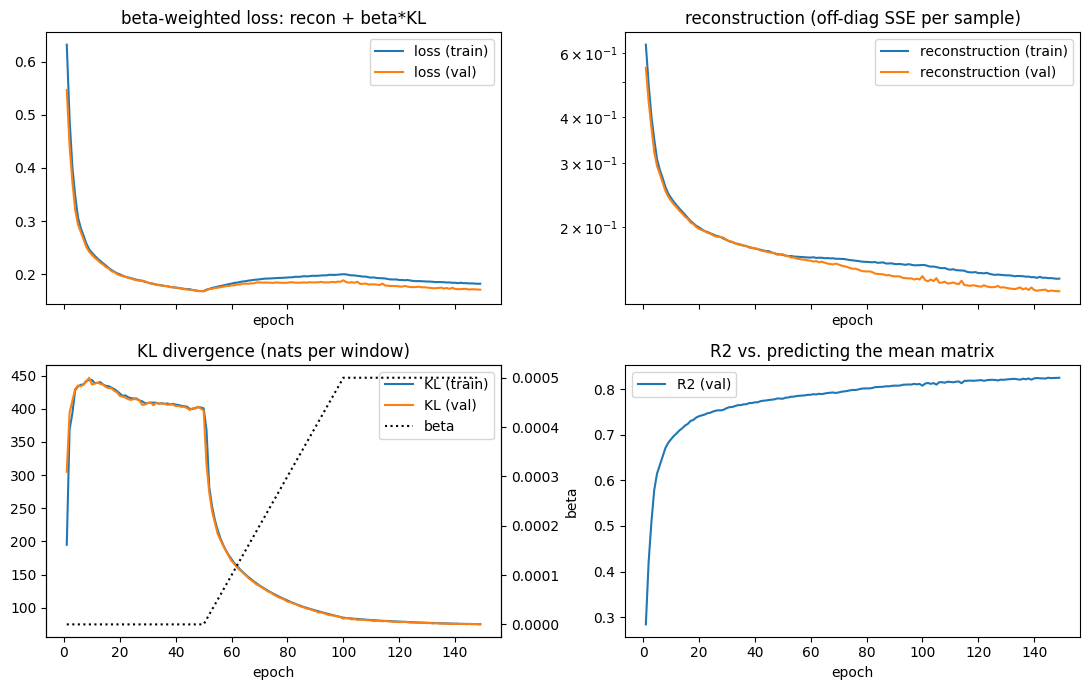

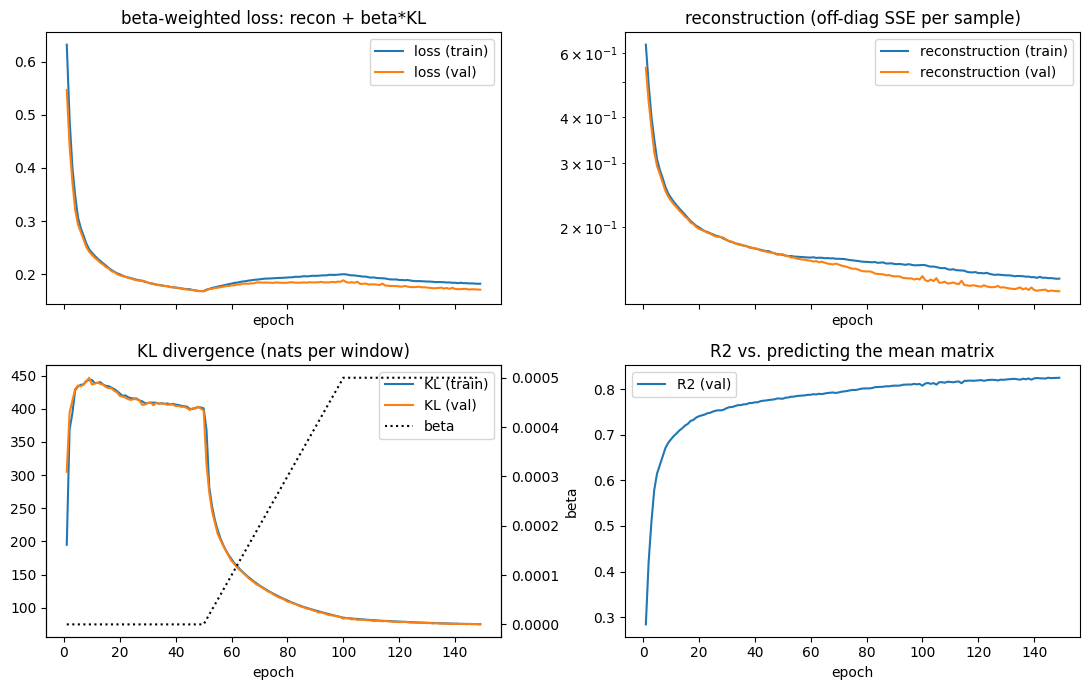

In [7]:
g = plot_history(history, skip=1)
g.show()

In [6]:
model = ConvVAE(latent=64, cond_dim=0).to(device)  # match your training args
state_dict = torch.load("best_vae_fold0.pt", map_location=device, weights_only=True)
model.load_state_dict(state_dict)
model.eval()

ConvVAE(
  (encoder): Sequential(
    (0): Conv2d(5, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1))
    (5): ReLU()
    (6): Flatten(start_dim=1, end_dim=-1)
  )
  (fc_mu): Linear(in_features=64, out_features=64, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=64, bias=True)
  (fc): Linear(in_features=64, out_features=64, bias=True)
  (decoder): Sequential(
    (0): ConvTranspose2d(64, 32, kernel_size=(5, 5), stride=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(32, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
    (4): ConvTranspose2d(16, 5, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  )
)

In [7]:
val_mu, val_logvar, val_y = encode_bags(model, val_loader, device)

active units: 54/64   total KL: 75.0 nats


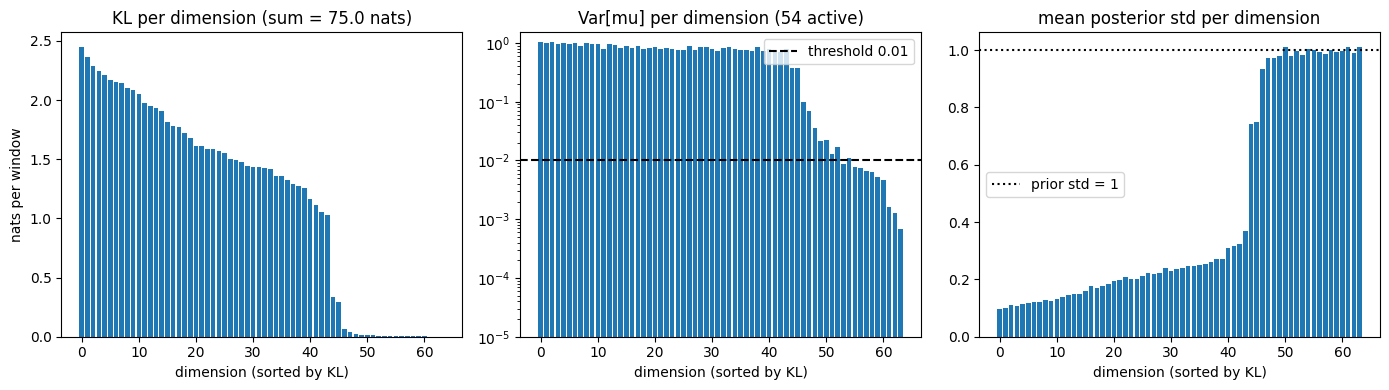

In [8]:
fig, order, n_active = plot_latent_usage(val_mu, val_logvar, thr=0.01)

# See how well it reconstructs

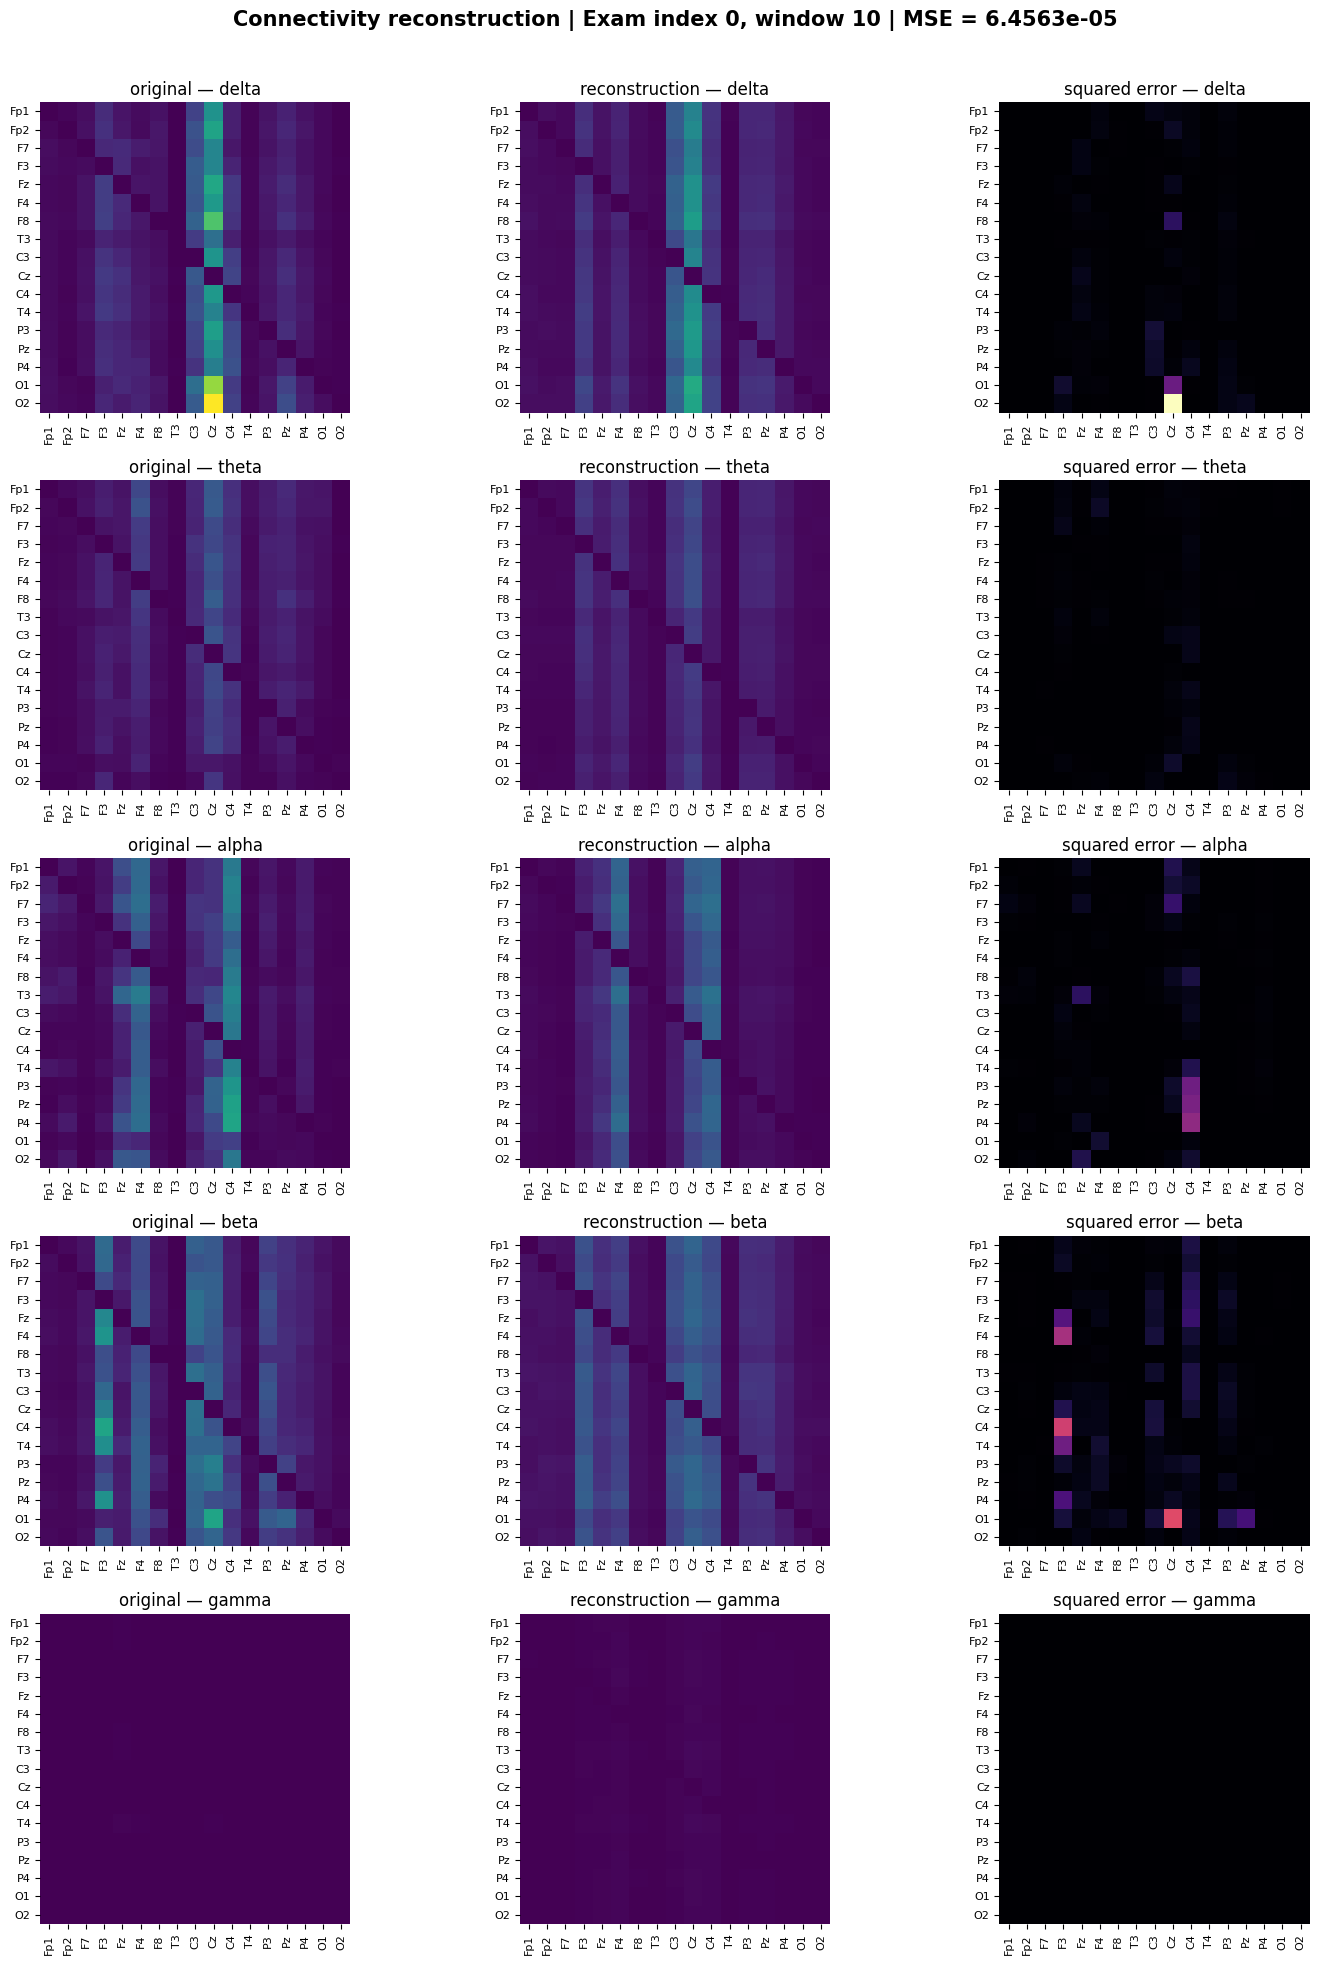

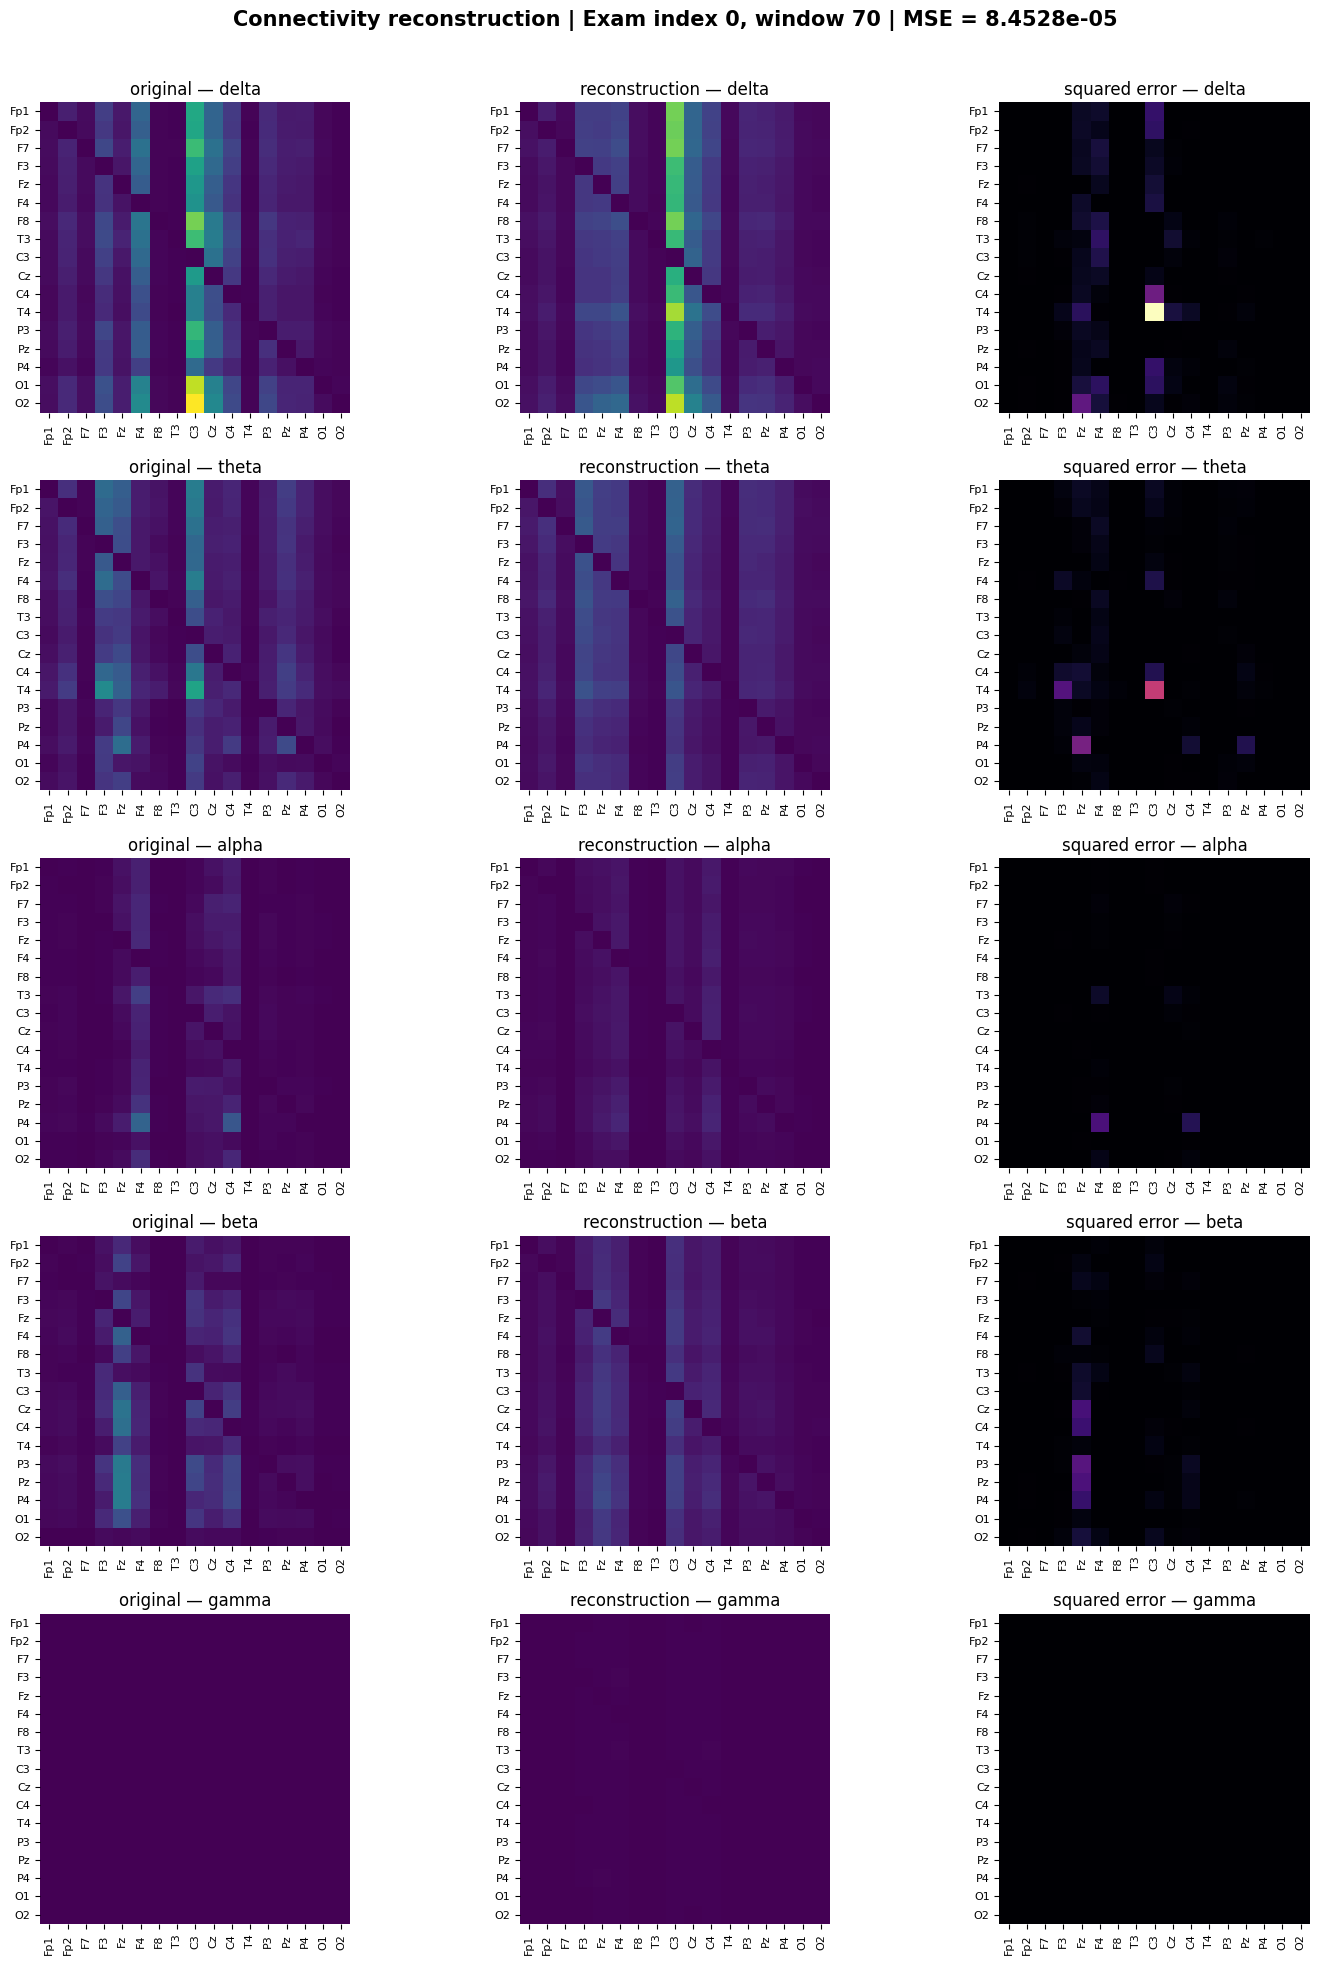

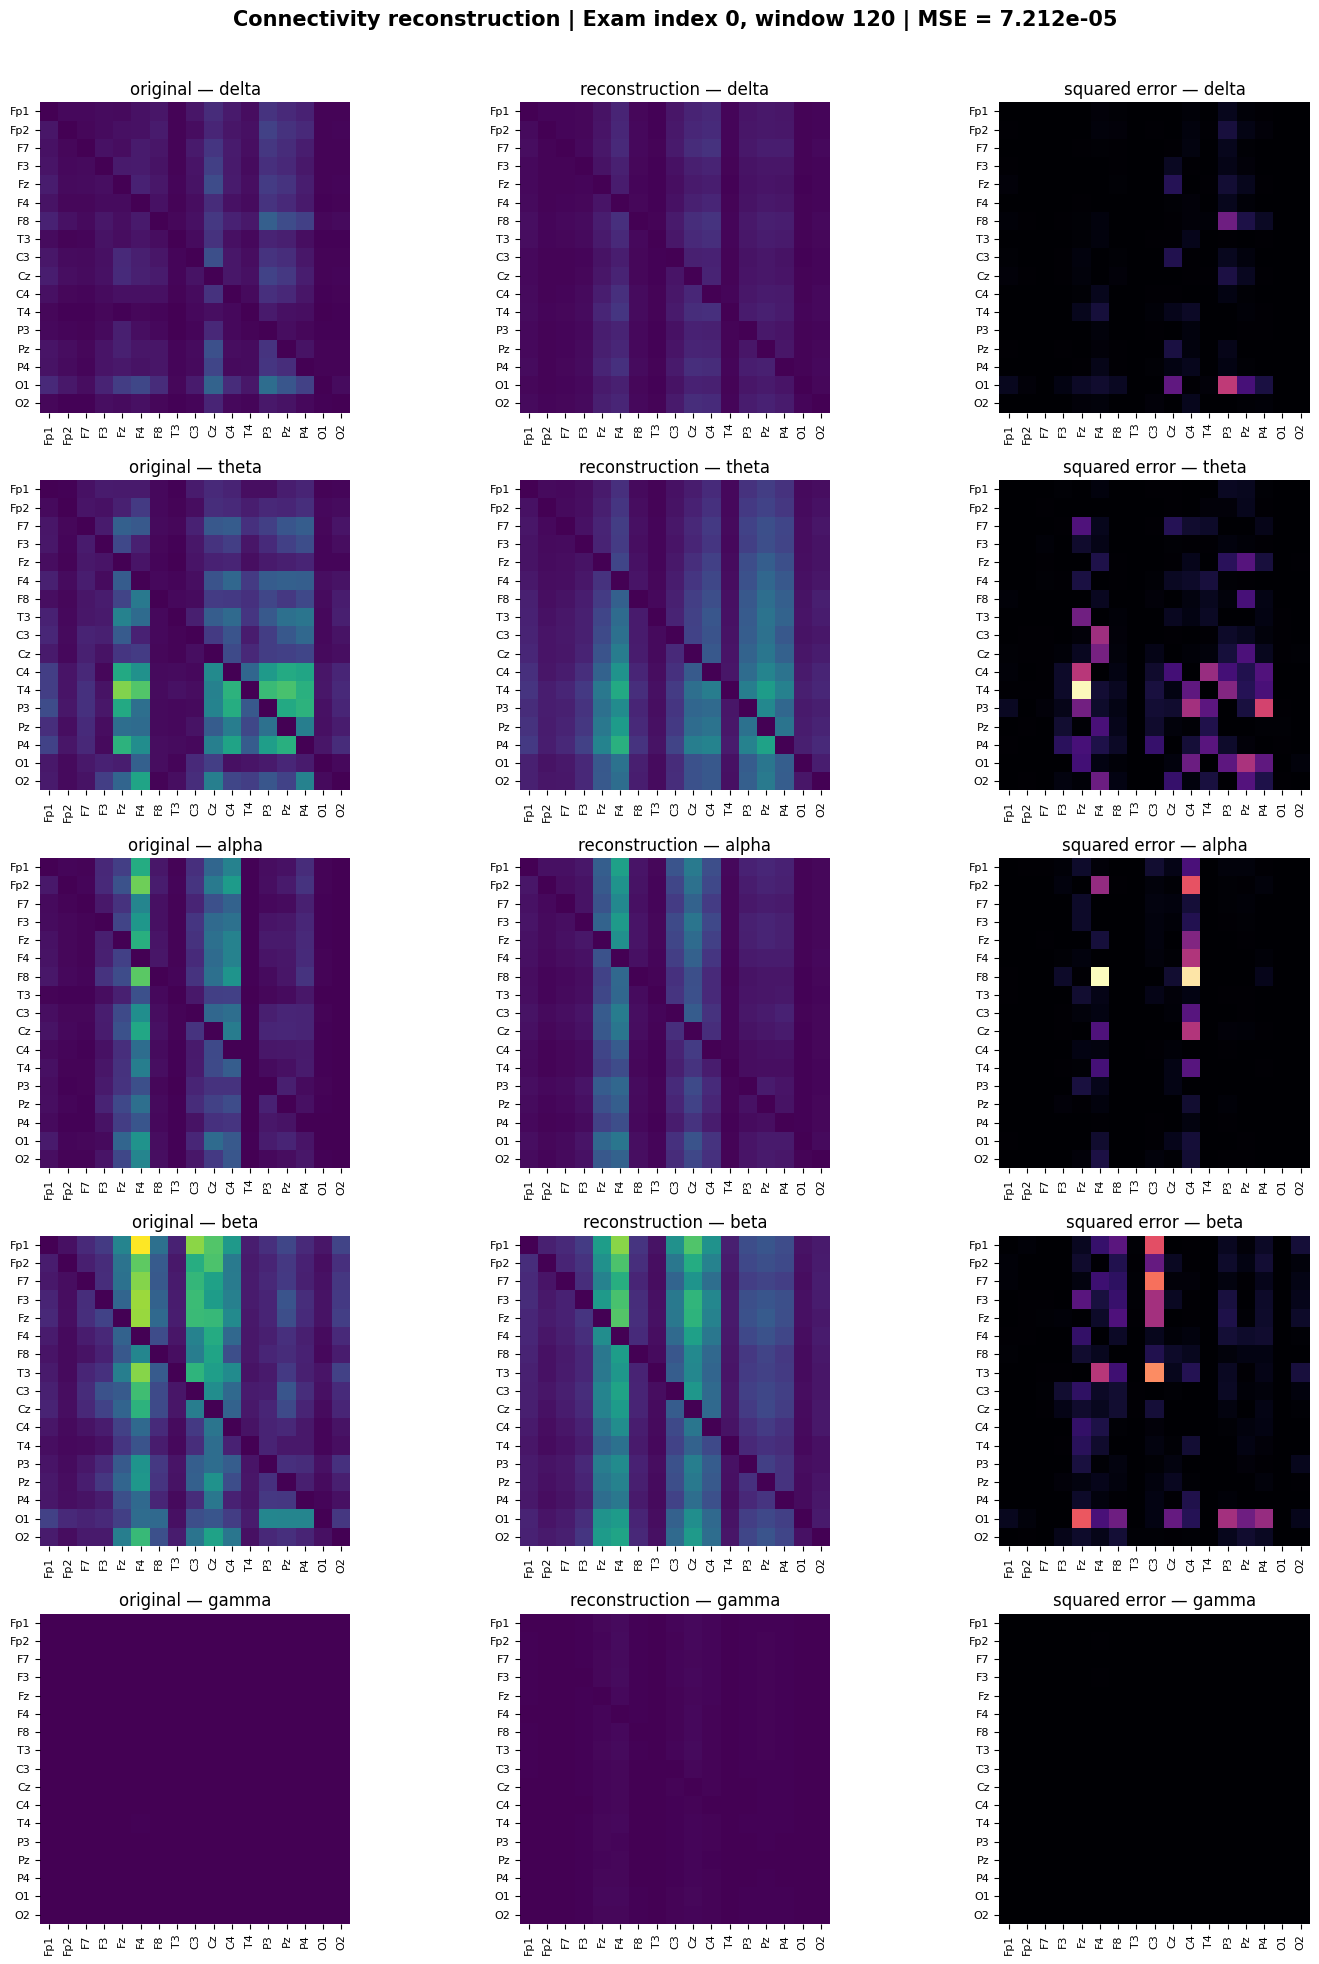

In [9]:
plot_reconstructions(model, val_loader, device, exam_idx=0, window_indices=(10, 70, 120))

# How does the latent space look?

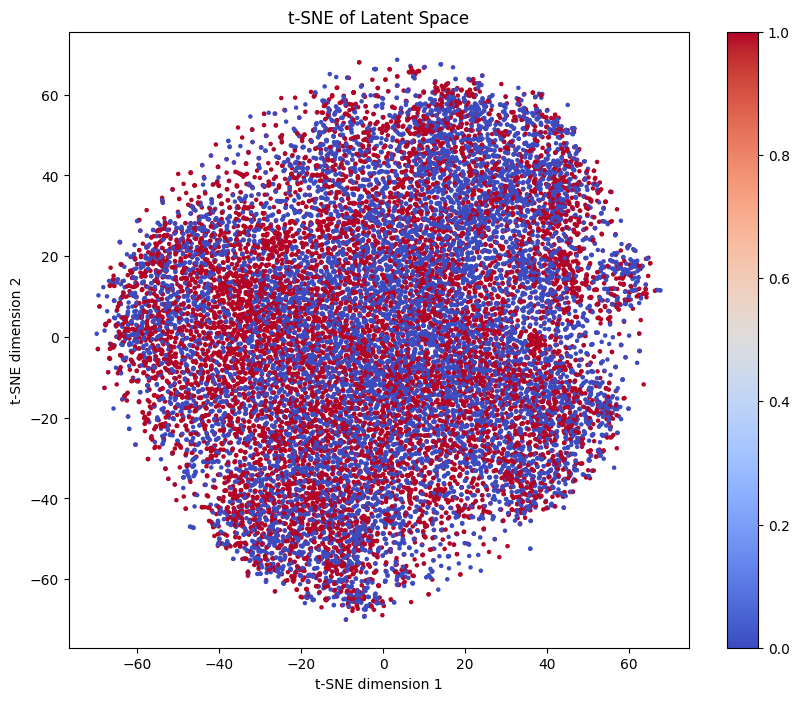

In [11]:
g = plot_tsne(val_mu, val_y)
g.show()

# Test out the generative skill

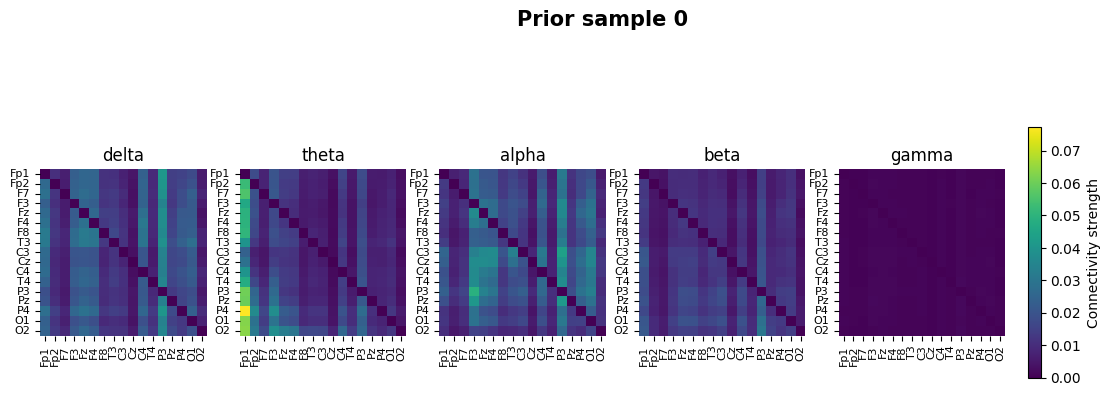

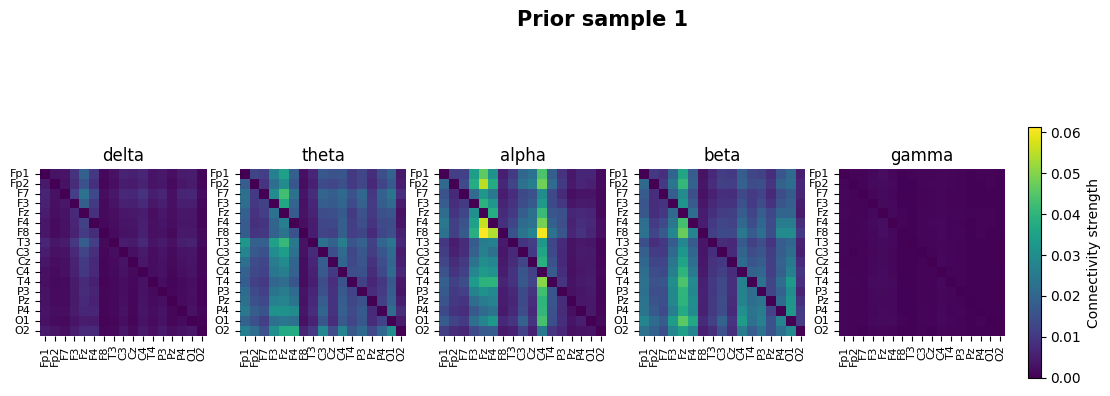

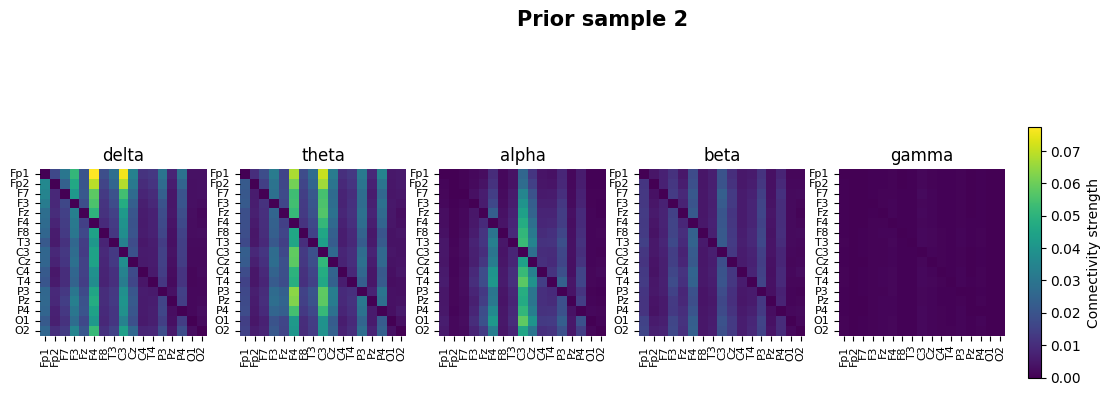

: 

In [ ]:
plot_prior_samples(model, device, num_samples=3)